# Activity 1 — Text Classification with RNN

In [ ]:
!pip install tiktoken -q

In [1]:
import torch
import torch.nn as nn

import pandas as pd
import numpy as np

import tiktoken

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt

from torch.utils.data import (
    TensorDataset,
    DataLoader
)

# Reproducibility
torch.manual_seed(1)
np.random.seed(1)

# Select CPU or GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Using device:", device)
     

PyTorch version: 2.14.1+cu130
Using device: cpu


In [3]:
df = pd.read_csv(
    "IMDB Dataset(1).csv",
    nrows=3000
)

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nFirst 5 rows:")
display(df.head())
     

Dataset shape: (3000, 2)

Columns:
Index(['review', 'sentiment'], dtype='str')

First 5 rows:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
print("Dataset shape:")
print(df.shape)

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape:
(3000, 2)

Sentiment distribution:
sentiment
positive    1508
negative    1492
Name: count, dtype: int64

Missing values:
review       0
sentiment    0
dtype: int64


In [5]:
df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

print(
    df[
        ["sentiment", "label"]
    ].head(10)
)

  sentiment  label
0  positive      1
1  positive      1
2  positive      1
3  negative      0
4  positive      1
5  positive      1
6  positive      1
7  negative      0
8  negative      0
9  positive      1


In [6]:
texts = df["review"].astype(str).values

labels = df["label"].values

print("Number of reviews:", len(texts))
print("Number of labels :", len(labels))

print("\nFirst review:")
print(texts[0][:500])

print("\nFirst label:")
print(labels[0])

Number of reviews: 3000
Number of labels : 3000

First review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ

First label:
1


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    texts,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining labels:")
print(np.bincount(y_train))

print("\nTesting labels:")
print(np.bincount(y_test))

Training samples: 2400
Testing samples : 600

Training labels:
[1194 1206]

Testing labels:
[298 302]


In [8]:
tokenizer = tiktoken.get_encoding(
    "cl100k_base"
)

print("Tokenizer:", tokenizer.name)
print("Vocabulary size:", tokenizer.n_vocab)

Tokenizer: cl100k_base
Vocabulary size: 100277


In [9]:
sample_text = X_train[0]

tokens = tokenizer.encode(
    sample_text
)

print("Original review:")
print(sample_text[:500])

print("\nFirst 30 token IDs:")
print(tokens[:30])

print("\nNumber of tokens:")
print(len(tokens))

Original review:
I have always loved the ironic symbolism and brilliant cinematography of Coppola's masterpiece. I was lucky enough to meet Martin Sheen outside the Santa Monica Civic Auditorium one night in 1981, as he waited for Charlie and Emilio to leave a concert. He was very humble about the praise I shared with him for this work of art, especially his portrayal of the young Captain. This is, without a doubt, a must see, a complete 10 and an important part of American Film History. "Charlie Don't Surf". Ro

First 30 token IDs:
[40, 617, 2744, 10456, 279, 59560, 83476, 323, 20333, 88122, 5814, 315, 82099, 8083, 596, 59831, 13, 358, 574, 18069, 3403, 311, 3449, 11826, 3005, 268, 4994, 279, 16376, 46844]

Number of tokens:
169


In [10]:
def encode_text(text):
    tokens = tokenizer.encode(text)

    # Reserve token ID 0 for padding
    tokens = [token + 1 for token in tokens]

    return tokens
     

In [11]:
encoded_sample = encode_text(
    sample_text
)

print("Original text:")
print(sample_text[:300])

print("\nEncoded token IDs:")
print(encoded_sample[:30])

print("\nNumber of tokens:")
print(len(encoded_sample))

Original text:
I have always loved the ironic symbolism and brilliant cinematography of Coppola's masterpiece. I was lucky enough to meet Martin Sheen outside the Santa Monica Civic Auditorium one night in 1981, as he waited for Charlie and Emilio to leave a concert. He was very humble about the praise I shared wi

Encoded token IDs:
[41, 618, 2745, 10457, 280, 59561, 83477, 324, 20334, 88123, 5815, 316, 82100, 8084, 597, 59832, 14, 359, 575, 18070, 3404, 312, 3450, 11827, 3006, 269, 4995, 280, 16377, 46845]

Number of tokens:
169


In [12]:

MAX_LENGTH = 200

print(
    "Maximum sequence length:",
    MAX_LENGTH
)
     

Maximum sequence length: 200


In [13]:
def pad_or_truncate(
    sequence,
    max_length=MAX_LENGTH
):

    # Truncate long sequences
    if len(sequence) > max_length:
        return sequence[:max_length]

    # Pad short sequences with 0
    return sequence + [0] * (
        max_length - len(sequence)
    )
     

In [14]:
test_sequence = encode_text(
    sample_text
)

processed_sequence = pad_or_truncate(
    test_sequence
)

print(
    "Original token count:",
    len(test_sequence)
)

print(
    "Processed token count:",
    len(processed_sequence)
)

print("\nFirst 20 tokens:")
print(processed_sequence[:20])

print("\nLast 20 tokens:")
print(processed_sequence[-20:])

Original token count: 169
Processed token count: 200

First 20 tokens:
[41, 618, 2745, 10457, 280, 59561, 83477, 324, 20334, 88123, 5815, 316, 82100, 8084, 597, 59832, 14, 359, 575, 18070]

Last 20 tokens:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [15]:
X_train_encoded = [
    pad_or_truncate(
        encode_text(text)
    )
    for text in X_train
]

print(
    "Training sequences:",
    len(X_train_encoded)
)

print(
    "Length of first sequence:",
    len(X_train_encoded[0])
)

Training sequences: 2400
Length of first sequence: 200


In [16]:
X_test_encoded = [
    pad_or_truncate(
        encode_text(text)
    )
    for text in X_test
]

print(
    "Testing sequences:",
    len(X_test_encoded)
)

print(
    "Length of first sequence:",
    len(X_test_encoded[0])
)

Testing sequences: 600
Length of first sequence: 200


In [17]:
X_train_tensor = torch.tensor(
    X_train_encoded,
    dtype=torch.long
)

X_test_tensor = torch.tensor(
    X_test_encoded,
    dtype=torch.long
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.float32
)

print("X_train:", X_train_tensor.shape)
print("X_test :", X_test_tensor.shape)

print("y_train:", y_train_tensor.shape)
print("y_test :", y_test_tensor.shape)

X_train: torch.Size([2400, 200])
X_test : torch.Size([600, 200])
y_train: torch.Size([2400])
y_test : torch.Size([600])


In [18]:
print("First training review:")
print(X_train_tensor[0])

print("\nFirst training label:")
print(y_train_tensor[0])

print("\nTensor data type:")
print(X_train_tensor.dtype)
     

First training review:
tensor([   41,   618,  2745, 10457,   280, 59561, 83477,   324, 20334, 88123,
         5815,   316, 82100,  8084,   597, 59832,    14,   359,   575, 18070,
         3404,   312,  3450, 11827,  3006,   269,  4995,   280, 16377, 46845,
        55930, 62493,  2412,   833,  3815,   305,   221,  3754,    17,    12,
          440,   569, 30316,   370, 25973,   324,  5868, 34430,   312,  5388,
          265, 21498,    14,  1284,   575,  1634, 39613,   923,   280, 29489,
          359,  6223,   450,  1462,   370,   421,   991,   316,  1990,    12,
         5424,   814, 75034,   316,   280,  3996, 22023,    14,  1116,   375,
           12,  2086,   265, 10713,    12,   265,  2012,  1519,    12,   265,
         4687,   221,   606,   324,   460,  3063,   962,   316,  3779, 17043,
        11347,    14,   331, 73729,  4419,   957, 65198,  3344,  8564,   424,
        12329,   544,   597, 11496,  1585,   321,  1821,  1024,   833,     9,
         1588,   540,  1206, 40917,   440

In [19]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(
    "Training batches:",
    len(train_loader)
)

print(
    "Testing batches:",
    len(test_loader)
)

Training batches: 75
Testing batches: 19


# Build the RNN Model

The model architecture is:

Embedding → RNN → Linear

The Embedding layer converts token IDs into dense vectors. The RNN processes the sequence of embeddings. The Linear layer produces the final sentiment score.

In [20]:
class MovieRNN(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128
    ):
        super().__init__()

        # Token IDs → dense vectors
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        # Process the sequence
        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # Final hidden state → sentiment score
        self.output = nn.Linear(
            hidden_dim,
            1
        )

    def forward(self, x):

        # Convert token IDs to embeddings
        x = self.embedding(x)

        # Process sequence using RNN
        _, hidden = self.rnn(x)

        # Use final hidden state
        output = self.output(
            hidden[-1]
        )

        return output.squeeze(1)
     

In [21]:
VOCAB_SIZE = tokenizer.n_vocab + 1

movie = MovieRNN(
    vocab_size=VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=128
).to(device)

print(movie)

MovieRNN(
  (embedding): Embedding(100278, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True)
  (output): Linear(in_features=128, out_features=1, bias=True)
)


In [22]:

total_parameters = sum(
    p.numel()
    for p in movie.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    total_parameters
)

Trainable parameters: 12868737


In [23]:
loss_fn = nn.BCEWithLogitsLoss()

print("Loss function:")
print(loss_fn)
     

Loss function:
BCEWithLogitsLoss()


In [24]:
optimizer = torch.optim.Adam(
    movie.parameters(),
    lr=0.0005
)

print("Optimizer:")
print(optimizer)

Optimizer:
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0005
    maximize: False
    weight_decay: 0
)


# Train the RNN

The model is trained using mini-batches.

For each batch:

    Perform a forward pass.
    Calculate the loss.
    Calculate gradients using backpropagation.
    Clip the gradients to improve training stability.
    Update the model parameters using Adam.


In [25]:
EPOCHS = 15

train_losses = []

for epoch in range(EPOCHS):

    movie.train()

    total_loss = 0

    for inputs, labels in train_loader:

        # Move batch to CPU/GPU
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        logits = movie(inputs)

        # Calculate loss
        loss = loss_fn(
            logits,
            labels
        )

        # Backpropagation
        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            movie.parameters(),
            max_norm=1.0
        )

        # Update weights
        optimizer.step()

        total_loss += loss.item()

    # Average loss for this epoch
    avg_loss = (
        total_loss /
        len(train_loader)
    )

    train_losses.append(
        avg_loss
    )

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"- Loss: {avg_loss:.4f}"
    )

Epoch 1/15 - Loss: 0.7000
Epoch 2/15 - Loss: 0.6733
Epoch 3/15 - Loss: 0.6462
Epoch 4/15 - Loss: 0.6119
Epoch 5/15 - Loss: 0.5710
Epoch 6/15 - Loss: 0.5327
Epoch 7/15 - Loss: 0.4783
Epoch 8/15 - Loss: 0.4365
Epoch 9/15 - Loss: 0.5021
Epoch 10/15 - Loss: 0.5813
Epoch 11/15 - Loss: 0.4059
Epoch 12/15 - Loss: 0.3567
Epoch 13/15 - Loss: 0.5931
Epoch 14/15 - Loss: 0.4876
Epoch 15/15 - Loss: 0.3527


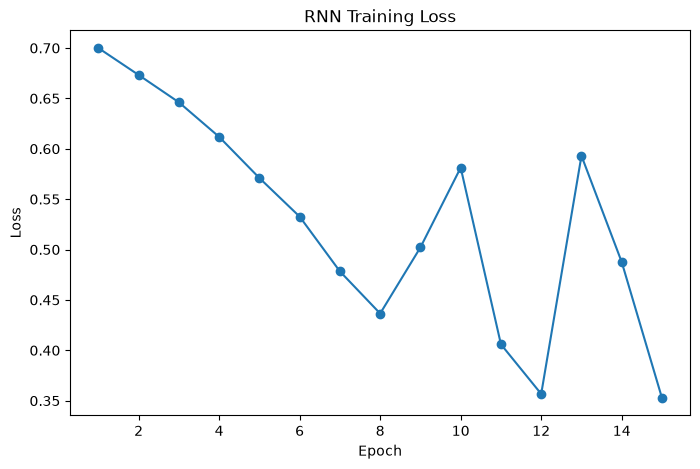

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN Training Loss")

plt.show()
     

In [27]:
movie.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        # Forward pass
        logits = movie(inputs)

        # Convert logits → probabilities
        probabilities = torch.sigmoid(
            logits
        )

        # Probability >= 0.5 → Positive
        predictions = (
            probabilities >= 0.5
        ).int()

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

all_predictions = np.array(
    all_predictions
)

all_labels = np.array(
    all_labels
)

print(
    "Number of test predictions:",
    len(all_predictions)
)

Number of test predictions: 600


In [28]:
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print(
    f"RNN Test Accuracy: "
    f"{accuracy:.4f}"
)

print(
    f"RNN Test Accuracy: "
    f"{accuracy * 100:.2f}%"
)

RNN Test Accuracy: 0.5367
RNN Test Accuracy: 53.67%


In [29]:
precision = precision_score(
    all_labels,
    all_predictions
)

recall = recall_score(
    all_labels,
    all_predictions
)

f1 = f1_score(
    all_labels,
    all_predictions
)

print(
    f"Precision: {precision:.4f}"
)

print(
    f"Recall   : {recall:.4f}"
)

print(
    f"F1 Score : {f1:.4f}"
)
     

Precision: 0.5290
Recall   : 0.7252
F1 Score : 0.6117


In [30]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=[
            "Negative",
            "Positive"
        ]
    )
)

              precision    recall  f1-score   support

    Negative       0.55      0.35      0.43       298
    Positive       0.53      0.73      0.61       302

    accuracy                           0.54       600
   macro avg       0.54      0.54      0.52       600
weighted avg       0.54      0.54      0.52       600



In [31]:
rnn_cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("RNN Confusion Matrix:")
print(rnn_cm)
     

RNN Confusion Matrix:
[[103 195]
 [ 83 219]]


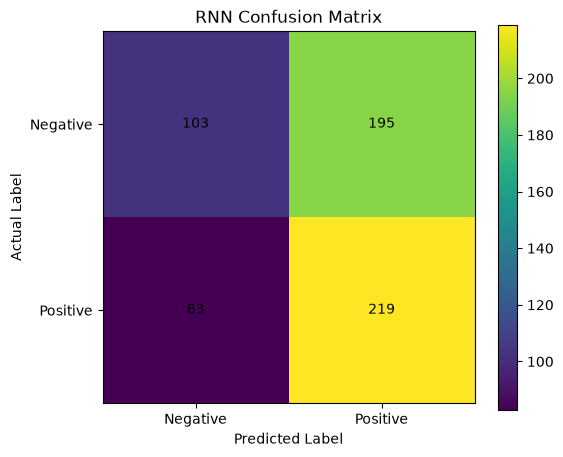

In [32]:
plt.figure(figsize=(6, 5))

plt.imshow(rnn_cm)

plt.title("RNN Confusion Matrix")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

for i in range(2):
    for j in range(2):

        plt.text(
            j,
            i,
            rnn_cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.show()
     

Activity 2 — Text Classification with LSTM

Repeat the text classification task using an LSTM instead of an RNN.

The same:

    IMDB dataset
    Train/Test split
    tiktoken tokenizer
    Padding/Truncation
    PyTorch tensors
    DataLoader

are reused.

Architecture:

Embedding → LSTM → Linear → Sentiment

In [33]:
class MovieLSTM(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128
    ):
        super().__init__()

        # Token IDs → Dense vectors
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        # Process sequence using LSTM
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # Final hidden state → sentiment score
        self.output = nn.Linear(
            hidden_dim,
            1
        )

    def forward(self, x):

        # Embedding
        x = self.embedding(x)

        # LSTM
        _, (hidden, cell) = self.lstm(x)

        # Final hidden state
        output = self.output(
            hidden[-1]
        )

        return output.squeeze(1)

In [34]:
lstm_model = MovieLSTM(
    vocab_size=VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=128
).to(device)

print(lstm_model)

MovieLSTM(
  (embedding): Embedding(100278, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (output): Linear(in_features=128, out_features=1, bias=True)
)


In [35]:
lstm_parameters = sum(
    p.numel()
    for p in lstm_model.parameters()
    if p.requires_grad
)

print(
    "Trainable LSTM parameters:",
    lstm_parameters
)

Trainable LSTM parameters: 12967809


In [36]:
lstm_loss_fn = nn.BCEWithLogitsLoss()

print("Loss function:")
print(lstm_loss_fn)

Loss function:
BCEWithLogitsLoss()


In [37]:
lstm_optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.0005
)

print("Optimizer:")
print(lstm_optimizer)

Optimizer:
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0005
    maximize: False
    weight_decay: 0
)


In [38]:
EPOCHS = 15

lstm_train_losses = []

print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", 0.0005)

Epochs: 15
Batch size: 32
Learning rate: 0.0005


In [39]:
for epoch in range(EPOCHS):

    lstm_model.train()

    total_loss = 0

    for inputs, labels in train_loader:

        # Move data to CPU/GPU
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Clear gradients
        lstm_optimizer.zero_grad()

        # Forward pass
        logits = lstm_model(inputs)

        # Calculate loss
        loss = lstm_loss_fn(
            logits,
            labels
        )

        # Backpropagation
        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            lstm_model.parameters(),
            max_norm=1.0
        )

        # Update parameters
        lstm_optimizer.step()

        total_loss += loss.item()

    avg_loss = (
        total_loss /
        len(train_loader)
    )

    lstm_train_losses.append(
        avg_loss
    )

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"- Loss: {avg_loss:.4f}"
    )
     

Epoch 1/15 - Loss: 0.6951
Epoch 2/15 - Loss: 0.6814
Epoch 3/15 - Loss: 0.6605
Epoch 4/15 - Loss: 0.6261
Epoch 5/15 - Loss: 0.5690
Epoch 6/15 - Loss: 0.4807
Epoch 7/15 - Loss: 0.4027
Epoch 8/15 - Loss: 0.3499
Epoch 9/15 - Loss: 0.2951
Epoch 10/15 - Loss: 0.2693
Epoch 11/15 - Loss: 0.2496
Epoch 12/15 - Loss: 0.2434
Epoch 13/15 - Loss: 0.2032
Epoch 14/15 - Loss: 0.1938
Epoch 15/15 - Loss: 0.1858


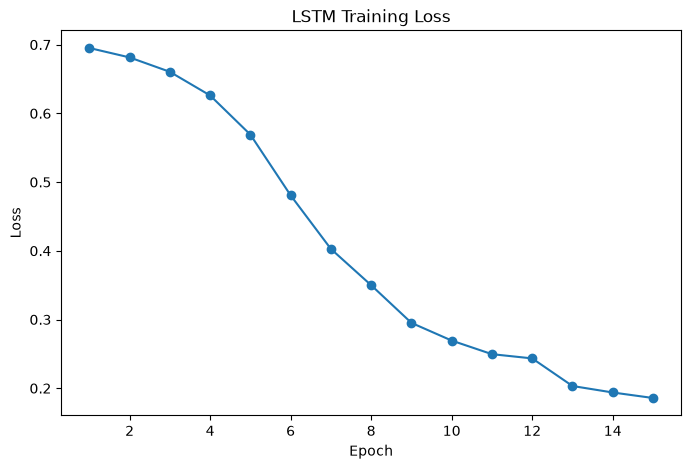

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    lstm_train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training Loss")

plt.show()

In [41]:
lstm_model.eval()

lstm_predictions = []
lstm_labels = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        # Forward pass
        logits = lstm_model(inputs)

        # Logits → probabilities
        probabilities = torch.sigmoid(
            logits
        )

        # Probability >= 0.5 → Positive
        predictions = (
            probabilities >= 0.5
        ).int()

        lstm_predictions.extend(
            predictions.cpu().numpy()
        )

        lstm_labels.extend(
            labels.numpy()
        )

lstm_predictions = np.array(
    lstm_predictions
)

lstm_labels = np.array(
    lstm_labels
)

print(
    "Test predictions:",
    len(lstm_predictions)
)

Test predictions: 600


In [42]:
lstm_accuracy = accuracy_score(
    lstm_labels,
    lstm_predictions
)

print(
    f"LSTM Accuracy: "
    f"{lstm_accuracy:.4f}"
)

print(
    f"LSTM Accuracy: "
    f"{lstm_accuracy * 100:.2f}%"
)

LSTM Accuracy: 0.5750
LSTM Accuracy: 57.50%


In [43]:
lstm_precision = precision_score(
    lstm_labels,
    lstm_predictions
)

lstm_recall = recall_score(
    lstm_labels,
    lstm_predictions
)

lstm_f1 = f1_score(
    lstm_labels,
    lstm_predictions
)

print(
    f"Precision: {lstm_precision:.4f}"
)

print(
    f"Recall   : {lstm_recall:.4f}"
)

print(
    f"F1 Score : {lstm_f1:.4f}"
)

Precision: 0.5907
Recall   : 0.5066
F1 Score : 0.5455


In [44]:
print(
    classification_report(
        lstm_labels,
        lstm_predictions,
        target_names=[
            "Negative",
            "Positive"
        ]
    )
)

              precision    recall  f1-score   support

    Negative       0.56      0.64      0.60       298
    Positive       0.59      0.51      0.55       302

    accuracy                           0.57       600
   macro avg       0.58      0.58      0.57       600
weighted avg       0.58      0.57      0.57       600



In [45]:
lstm_cm = confusion_matrix(
    lstm_labels,
    lstm_predictions
)

print("LSTM Confusion Matrix:")
print(lstm_cm)
     

LSTM Confusion Matrix:
[[192 106]
 [149 153]]


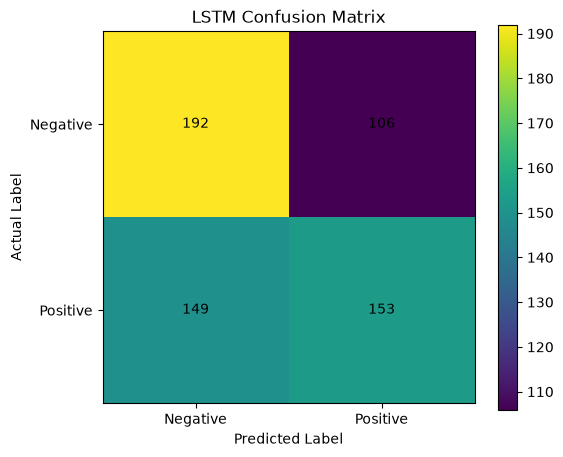

In [46]:
plt.figure(figsize=(6, 5))

plt.imshow(lstm_cm)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

for i in range(2):
    for j in range(2):

        plt.text(
            j,
            i,
            lstm_cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.show()

In [47]:
print("================================")
print("       RNN vs LSTM")
print("================================")

print(
    f"RNN  Accuracy : "
    f"{accuracy * 100:.2f}%"
)

print(
    f"LSTM Accuracy : "
    f"{lstm_accuracy * 100:.2f}%"
)

print("================================")

if lstm_accuracy > accuracy:

    print(
        "LSTM achieved higher test accuracy."
    )

elif accuracy > lstm_accuracy:

    print(
        "RNN achieved higher test accuracy."
    )

else:

    print(
        "Both models achieved the same accuracy."
    )

       RNN vs LSTM
RNN  Accuracy : 53.67%
LSTM Accuracy : 57.50%
LSTM achieved higher test accuracy.


In [48]:
def predict_lstm_sentiment(text):

    lstm_model.eval()

    # Tokenize
    encoded = encode_text(text)

    # Pad / truncate
    processed = pad_or_truncate(
        encoded
    )

    # Convert to tensor
    input_tensor = torch.tensor(
        [processed],
        dtype=torch.long
    ).to(device)

    with torch.no_grad():

        logit = lstm_model(
            input_tensor
        )

        probability = torch.sigmoid(
            logit
        ).item()

    if probability >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    return sentiment, probability

In [49]:
review = (
    "This movie was absolutely amazing. "
    "I really enjoyed every moment of it."
)

sentiment, probability = (
    predict_lstm_sentiment(review)
)

print("Review:")
print(review)

print("\nLSTM Prediction:")
print("Sentiment:", sentiment)
print(
    "Probability:",
    f"{probability:.4f}"
)
     

Review:
This movie was absolutely amazing. I really enjoyed every moment of it.

LSTM Prediction:
Sentiment: Negative
Probability: 0.0919


In [50]:
review = (
    "This movie was terrible, boring "
    "and a complete waste of time."
)

sentiment, probability = (
    predict_lstm_sentiment(review)
)

print("Review:")
print(review)

print("\nLSTM Prediction:")
print("Sentiment:", sentiment)
print(
    "Probability:",
    f"{probability:.4f}"
)

Review:
This movie was terrible, boring and a complete waste of time.

LSTM Prediction:
Sentiment: Negative
Probability: 0.0919


In [51]:
review = (
    "The acting was excellent "
    "and the story was fantastic."
)

sentiment, probability = (
    predict_lstm_sentiment(review)
)

print("Review:")
print(review)

print("\nLSTM Prediction:")
print("Sentiment:", sentiment)
print(
    "Probability:",
    f"{probability:.4f}"
)

Review:
The acting was excellent and the story was fantastic.

LSTM Prediction:
Sentiment: Negative
Probability: 0.0919
